In [ ]:
#Rotulagem de componentes conectados (Connected Component Labeling)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label
from skimage.morphology import remove_small_objects
from skimage.color import label2rgb
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize
from skimage.util import invert
from skan import Skeleton, summarize
from itertools import combinations

def detectar_fibras_conectadas(caminho_imagem, limiar_bin=50, tamanho_minimo=100):
    # 1. Abrir imagem e converter para grayscale
    img = Image.open(caminho_imagem).convert("L")
    imagem = np.array(img)
    # 2. Binarizar: pixels brancos são potenciais fibras
    binaria = imagem > limiar_bin  # threshold simples
    # 3. Remove ruído (objetos pequenos)
    binaria_limpa = remove_small_objects(binaria, min_size=tamanho_minimo)
    # 4. Rotula regiões conectadas (conectividade 8)
    rotulada = label(binaria_limpa, connectivity=2)
    # 5. Visualiza com cores diferentes para cada fibra
    imagem_colorida = label2rgb(rotulada, bg_label=0)
    # 6. Mostra os resultados
    fig, axs = plt.subplots(1, 3, figsize=(20, 10), dpi=150)
    axs[0].imshow(imagem, cmap="gray")
    axs[0].set_title("Imagem original")
    axs[1].imshow(binaria_limpa, cmap="gray")
    axs[1].set_title("Binária (fibras brancas)")
    axs[2].imshow(imagem_colorida)
    axs[2].set_title("Fibras rotuladas")
    for ax in axs:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return rotulada

def marcar_centroides_por_faixa(matriz_binaria, imagem_original, nrow_por_faixa):
    """
    Varre uma matriz binária em faixas, encontra os centroides das regiões
    e os plota sobre a imagem original.

    Args:
        matriz_binaria (np.ndarray): A imagem binária (True/False ou 1/0).
        imagem_original (np.ndarray): A imagem em escala de cinza para ser usada como fundo.
        nrow_por_faixa (int): O número de linhas em cada faixa a ser analisada.
    """
    altura_total, largura_total = matriz_binaria.shape
    todos_centroides = []

    # 2. Varre a matriz de nrow_por_faixa em nrow_por_faixa linhas
    print(f"Analisando imagem em faixas de {nrow_por_faixa} linhas...")
    for i in range(0, altura_total, nrow_por_faixa):
        # Define a faixa atual
        fim_faixa = min(i + nrow_por_faixa, altura_total)
        faixa_binaria = matriz_binaria[i:fim_faixa, :]

        # 3. Marca os centroides das regiões na faixa
        # label() encontra todos os grupos de pixels conectados
        rotulos_na_faixa = label(faixa_binaria)
        
        # regionprops() calcula propriedades (como o centroide) para cada região rotulada
        propriedades = regionprops(rotulos_na_faixa)
        
        for prop in propriedades:
            # O centroide é (linha, coluna) relativo à FAIXA
            centroide_local_y, centroide_local_x = prop.centroid
            
            # Ajusta a coordenada Y para a posição na IMAGEM COMPLETA
            centroide_global_y = centroide_local_y + i
            centroide_global_x = centroide_local_x
            
            todos_centroides.append((centroide_global_x, centroide_global_y))

    print(f"Total de {len(todos_centroides)} centroides encontrados.")
    
    # 4. Plota a imagem final com os centroides
    fig, ax = plt.subplots(figsize=(12, 12), dpi=150)
    ax.imshow(imagem_original, cmap='gray')
    
    if todos_centroides:
        # Descompacta a lista de tuplas em duas listas (coordenadas x e y)
        x_coords, y_coords = zip(*todos_centroides)
        
        # 's' é o tamanho do ponto, 'c' é a cor
        ax.scatter(x_coords, y_coords, s=1, c='red', marker='.')
    
    ax.set_title(f"Centroides detectados em faixas de {nrow_por_faixa} linhas")
    ax.axis('off')
    plt.tight_layout()
    plt.show()

def marcar_centroides_por_grid(matriz_binaria, imagem_original, grid_rows, grid_cols, plotar_grid=True):
    """
    Divide uma matriz binária em um grid, encontra os centroides das regiões
    em cada célula e os plota sobre a imagem original.

    Args:
        matriz_binaria (np.ndarray): A imagem binária (True/False ou 1/0).
        imagem_original (np.ndarray): A imagem em escala de cinza para fundo.
        grid_rows (int): O número de linhas na grade de análise.
        grid_cols (int): O número de colunas na grade de análise.
        plotar_grid (bool): Se True, desenha as linhas da grade na imagem final.
    """
    altura_total, largura_total = matriz_binaria.shape
    todos_centroides = []

    # Calcula as dimensões de cada célula da grade em pixels
    altura_celula = altura_total // grid_rows
    largura_celula = largura_total // grid_cols

    print(f"Analisando imagem em um grid de {grid_rows}x{grid_cols}...")
    print(f"Cada célula tem aproximadamente {altura_celula}x{largura_celula} pixels.")

    # 2. Varre a matriz usando um grid (loop aninhado)
    for i in range(grid_rows):
        for j in range(grid_cols):
            # Define as coordenadas da célula atual
            y_inicio = i * altura_celula
            y_fim = (i + 1) * altura_celula
            x_inicio = j * largura_celula
            x_fim = (j + 1) * largura_celula

            # Garante que a última célula vá até a borda da imagem
            if i == grid_rows - 1:
                y_fim = altura_total
            if j == grid_cols - 1:
                x_fim = largura_total

            # Extrai a célula da imagem binária
            celula_binaria = matriz_binaria[y_inicio:y_fim, x_inicio:x_fim]

            # 3. Marca os centroides das regiões na célula
            rotulos_na_celula = label(celula_binaria)
            propriedades = regionprops(rotulos_na_celula)
            
            for prop in propriedades:
                # Centroide (linha, coluna) relativo à CÉLULA
                centroide_local_y, centroide_local_x = prop.centroid
                
                # Converte para a coordenada global da IMAGEM COMPLETA
                # somando o deslocamento (offset) da célula
                centroide_global_y = centroide_local_y + y_inicio
                centroide_global_x = centroide_local_x + x_inicio
                
                todos_centroides.append((centroide_global_x, centroide_global_y))

    print(f"Total de {len(todos_centroides)} centroides encontrados.")

    # 4. Plota a imagem final com os centroides
    fig, ax = plt.subplots(figsize=(12, 12), dpi=150)
    ax.imshow(imagem_original, cmap='gray')

    if todos_centroides:
        x_coords, y_coords = zip(*todos_centroides)
        ax.scatter(x_coords, y_coords, s=1, c='red', marker='.')

    # Adicional: desenha as linhas do grid para visualização
    if plotar_grid:
        for i in range(1, grid_rows):
            ax.axhline(i * altura_celula, color='cyan', linestyle='--', linewidth=0.2)
        for j in range(1, grid_cols):
            ax.axvline(j * largura_celula, color='cyan', linestyle='--', linewidth=0.2)

    ax.set_title(f"Centroides detectados em um grid de {grid_rows}x{grid_cols}")
    ax.axis('off')
    plt.tight_layout()
    plt.show()

def podar_esqueleto_por_orientacao(esqueleto_img, angulo_limite_graus=45):
    """
    Args:
        esqueleto_img (np.ndarray): A imagem binária do esqueleto.
        angulo_limite_graus (int): O desvio máximo em graus em relação à linha
                                   perfeita (180°) para considerar dois ramos
                                   como uma continuação.

    Returns:
        np.ndarray: A imagem do esqueleto podado.
    """
    # 1. Analisar o esqueleto
    skeleton_obj = Skeleton(esqueleto_img)
    summary = summarize(skeleton_obj)

    # Se não houver ramos, retorna a imagem original
    if summary.shape[0] == 0:
        print("Nenhum ramo encontrado no esqueleto.")
        return esqueleto_img

    esqueleto_podado = np.copy(esqueleto_img)

    # 2. Encontrar pontos de junção (NOVA LÓGICA)
    # Concatena todas as IDs de nós (origem e destino) em uma única lista
    todos_os_nos = pd.concat([summary['node-id-src'], summary['node-id-dst']], ignore_index=True)
    
    # Conta a ocorrência de cada ID de nó
    contagem_nos = todos_os_nos.value_counts()
    
    # Junções são os nós que aparecem mais de 2 vezes
    pontos_de_juncao = contagem_nos[contagem_nos > 2].index.tolist()

    print(f"Encontrados {len(pontos_de_juncao)} pontos de junção para análise.")

    # 3. Analisar cada junção
    for junction_id in pontos_de_juncao:
        j_coords = skeleton_obj.coordinates[junction_id]
        
        # Encontra todos os ramos conectados a essa junção
        ramos_conectados = summary[(summary['node-id-src'] == junction_id) | (summary['node-id-dst'] == junction_id)]
        
        if len(ramos_conectados) < 3:
            continue

        ramos_info = []
        for _, ramo in ramos_conectados.iterrows():
            # Pega o ID do ponto final do ramo (o que não é a junção)
            other_node_id = ramo['node-id-dst'] if ramo['node-id-src'] == junction_id else ramo['node-id-src']
            other_coords = skeleton_obj.coordinates[int(other_node_id)]

            # Calcula o vetor e o ângulo do ramo
            dy = other_coords[0] - j_coords[0]
            dx = other_coords[1] - j_coords[1]
            angle = np.degrees(np.arctan2(-dy, dx))
            
            ramos_info.append({'id': ramo['skeleton-id'], 'angle': angle})

        # 4. Aplicar a lógica de poda (esta parte não muda)
        melhor_par = None
        menor_diff_de_180 = 180

        for r1, r2 in combinations(ramos_info, 2):
            diff = abs(r1['angle'] - r2['angle'])
            diff_de_180 = abs(diff - 180)
            if diff_de_180 > 180:
                diff_de_180 = 360 - diff_de_180

            if diff_de_180 < menor_diff_de_180:
                menor_diff_de_180 = diff_de_180
                melhor_par = {r1['id'], r2['id']}

        if melhor_par and menor_diff_de_180 < angulo_limite_graus:
            for ramo in ramos_info:
                # if ramo['id'] not in melhor_par:
                print(f"Podando ramo {ramo['id']} na junção {junction_id} (ângulo: {ramo['angle']:.1f}°)")
                path_coords = skeleton_obj.path_coordinates(int(ramo['id']))
                esqueleto_podado[path_coords[:, 0], path_coords[:, 1]] = 0
        else:
            print(f"Nenhum par colinear encontrado na junção {junction_id}. Nenhum ramo podado.")

    return esqueleto_podado

def colorir_juncoes_esqueleto(esqueleto_img, tamanho_ponto=3):
    """
    Encontra e colore os pontos de junção (nós com 3+ conexões) em um esqueleto.

    Args:
        esqueleto_img (np.ndarray): A imagem binária do esqueleto (pixels do esqueleto
                                  devem ser True ou 1).
        tamanho_ponto (int): O tamanho do quadrado vermelho a ser desenhado sobre
                             cada ponto de junção para melhor visualização.

    Returns:
        np.ndarray: Uma imagem RGB com o esqueleto em branco e as junções em vermelho.
        np.ndarray: As coordenadas (y, x) dos pontos de junção encontrados.
    """
    # 1. Analisa a imagem do esqueleto com a biblioteca skan
    # skeleton_obj contém todas as informações sobre a topologia do esqueleto
    try:
        skeleton_obj = Skeleton(esqueleto_img)
    except ValueError:
        print("Aviso: Imagem de esqueleto vazia ou inválida. Retornando imagem original.")
        return gray2rgb((esqueleto_img * 255).astype(np.uint8)), np.array([])


    # 2. Obtém o "grau" de cada nó do esqueleto.
    # O grau é o número de ramos que se conectam àquele ponto.
    degrees = skeleton_obj.degrees

    # 3. Encontra os índices dos nós que são junções (grau >= 3)
    indices_juncoes = np.where(degrees >= 3)[0]

    if len(indices_juncoes) == 0:
        print("Nenhuma junção (grau >= 3) foi encontrada no esqueleto.")
        # Retorna a imagem sem alterações se não houver junções
        return gray2rgb((esqueleto_img * 255).astype(np.uint8)), np.array([])


    # 4. Obtém as coordenadas (y, x) desses pontos de junção
    coords_juncoes = skeleton_obj.coordinates[indices_juncoes].astype(int)

    # 5. Prepara a imagem de saída, convertendo o esqueleto binário para RGB
    # O esqueleto (True/1) se torna branco (255, 255, 255)
    esqueleto_colorido = gray2rgb((esqueleto_img * 255).astype(np.uint8))

    # 6. Colore os pontos de junção de vermelho
    print(f"Encontrados {len(coords_juncoes)} pontos de junção. Colorindo de vermelho...")

    # Calcula o deslocamento para centralizar o ponto
    offset = tamanho_ponto // 2
    
    for y, x in coords_juncoes:
        # Define os limites do quadrado, garantindo que não saia da imagem
        y_min = max(0, y - offset)
        y_max = min(esqueleto_colorido.shape[0], y + offset + 1)
        x_min = max(0, x - offset)
        x_max = min(esqueleto_colorido.shape[1], x + offset + 1)
        
        # Pinta a área definida de vermelho
        esqueleto_colorido[y_min:y_max, x_min:x_max] = (255, 0, 0) # Cor Vermelha

    return esqueleto_colorido, coords_juncoes

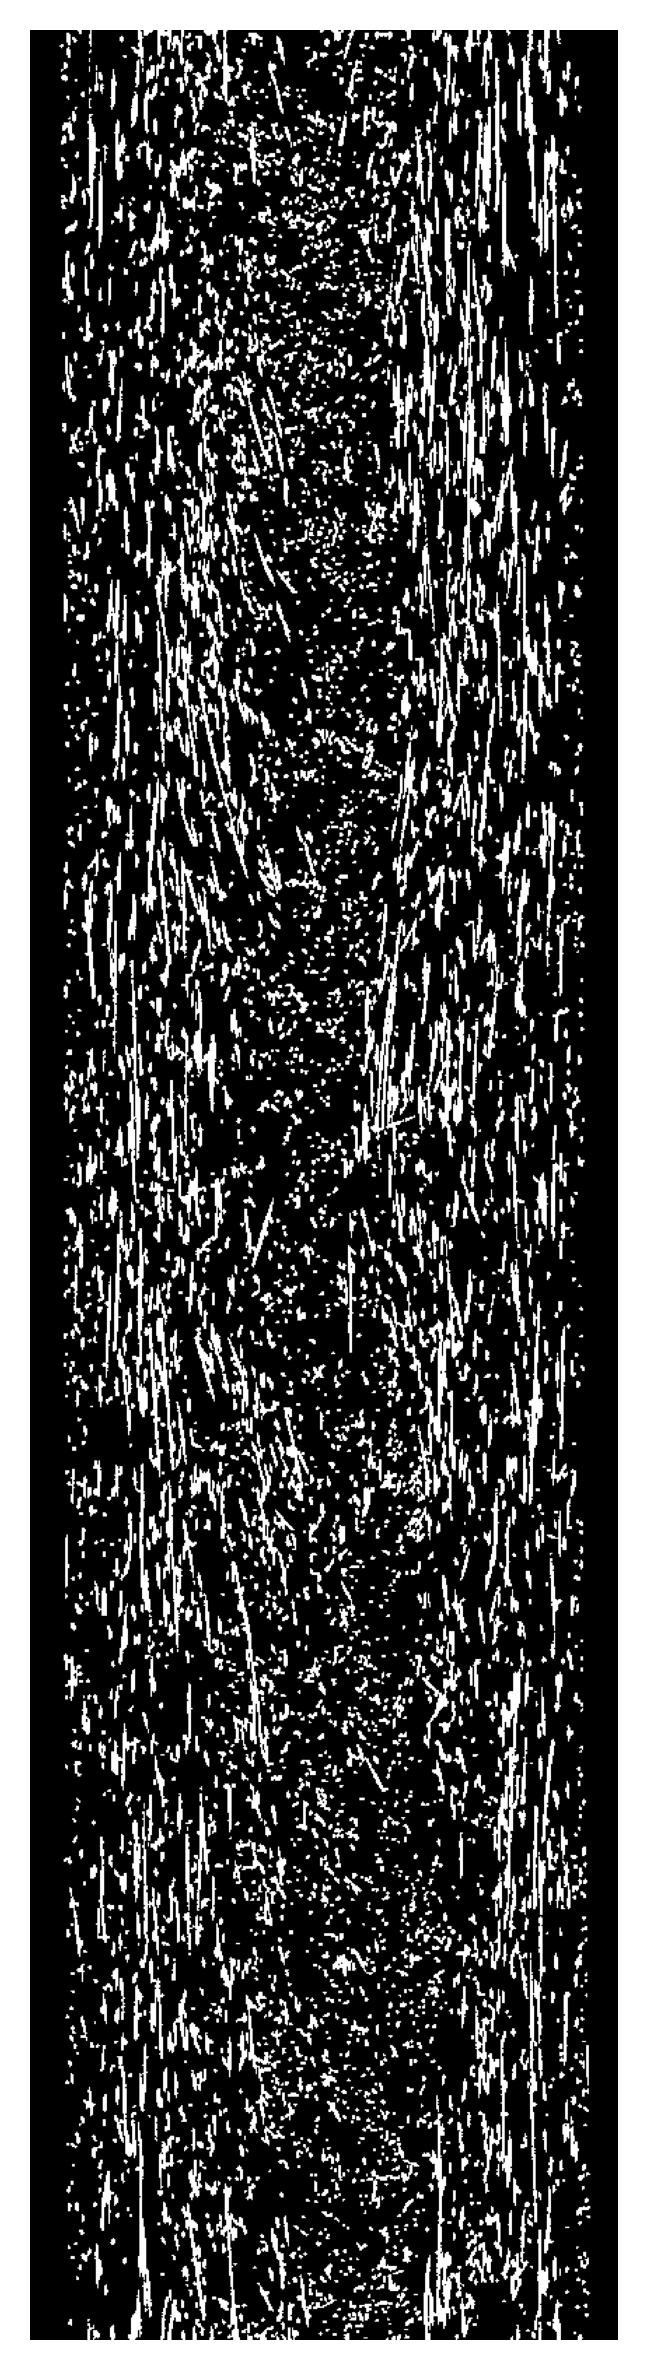

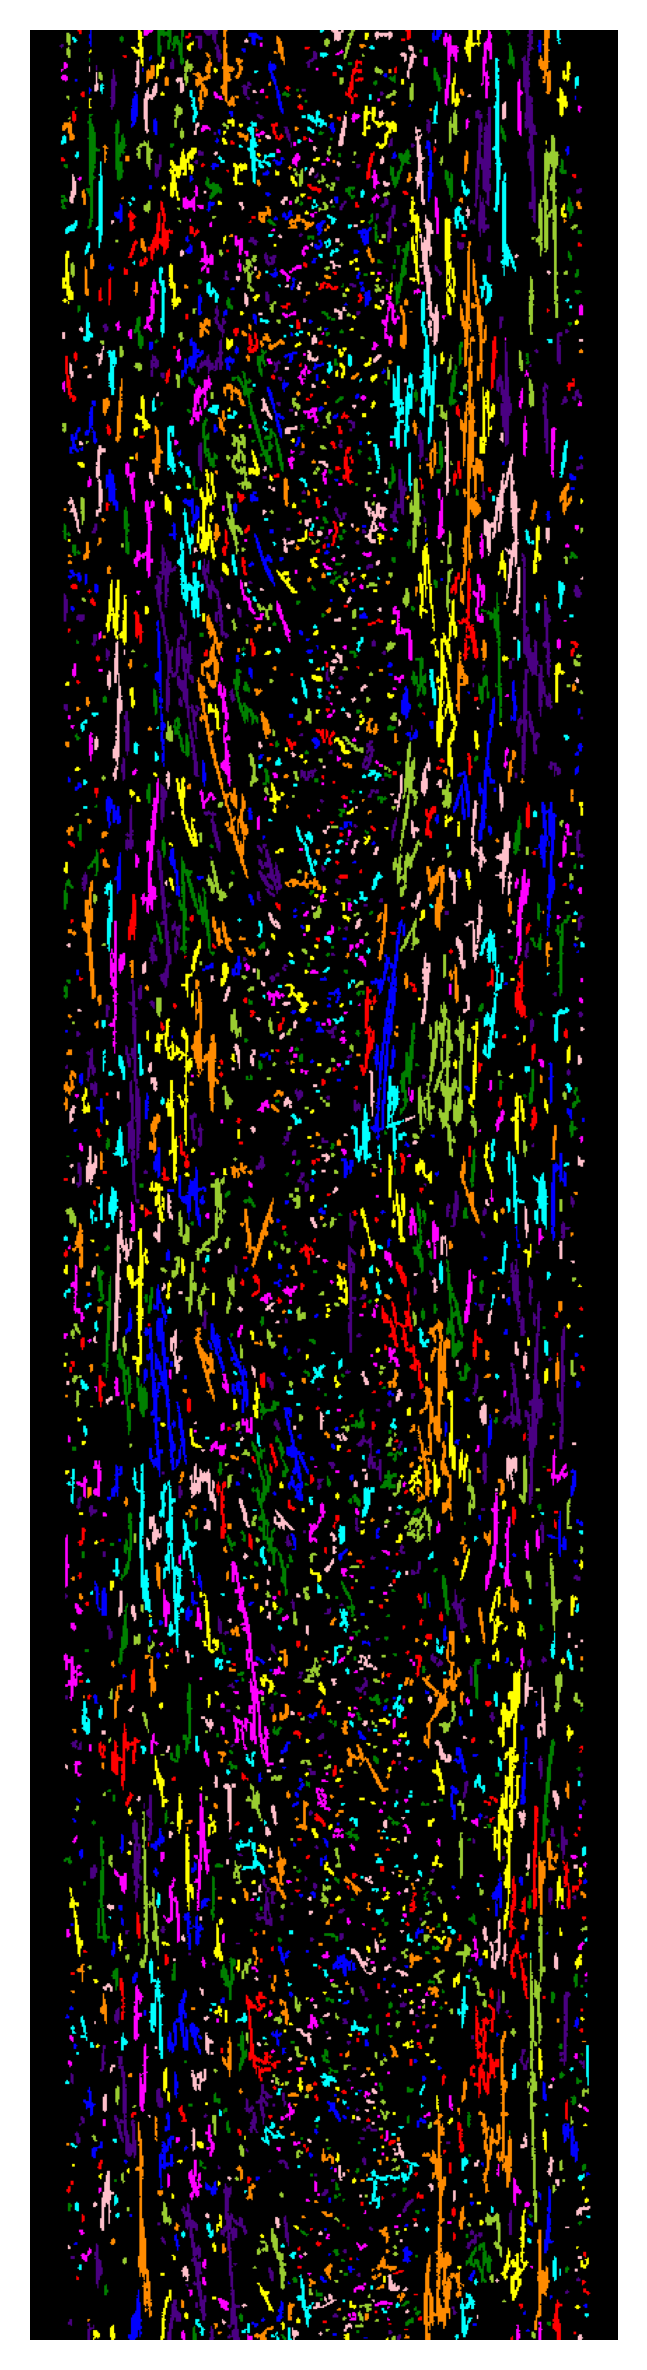

In [31]:
img = Image.open("./fiber_img/slice_400.tiff").convert("L")
imagem = np.array(img)
binaria = imagem > 200
binaria_limpa = remove_small_objects(binaria, min_size=50)

plt.figure(figsize=(10, 10), dpi=300)
plt.imshow(binaria_limpa, cmap='gray')
plt.axis('off')
plt.show()

rotulada = label(binaria_limpa, connectivity=2)

plt.figure(figsize=(10, 10), dpi=300)
plt.imshow(label2rgb(rotulada, bg_label=0), cmap='gray')
plt.axis('off')
plt.show()

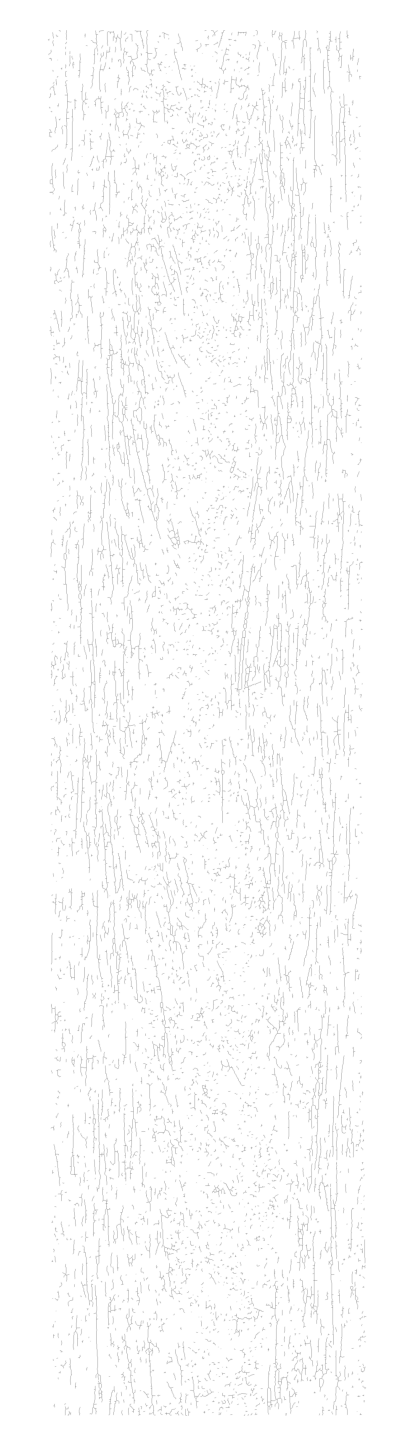

In [68]:
img = Image.open("./fiber_img/slice_400.tiff").convert("L")
imagem = np.array(img)
binaria = imagem > 200
binaria_limpa = remove_small_objects(binaria, min_size=50)

# marcar_centroides_por_faixa(binaria_limpa, imagem, nrow_por_faixa=100)

esqueleto = skeletonize(binaria_limpa)

esqueleto_inv = invert(esqueleto)

plt.figure(figsize=(6, 6), dpi=300)
plt.imshow(esqueleto, cmap='binary')
plt.axis('off')
plt.show()

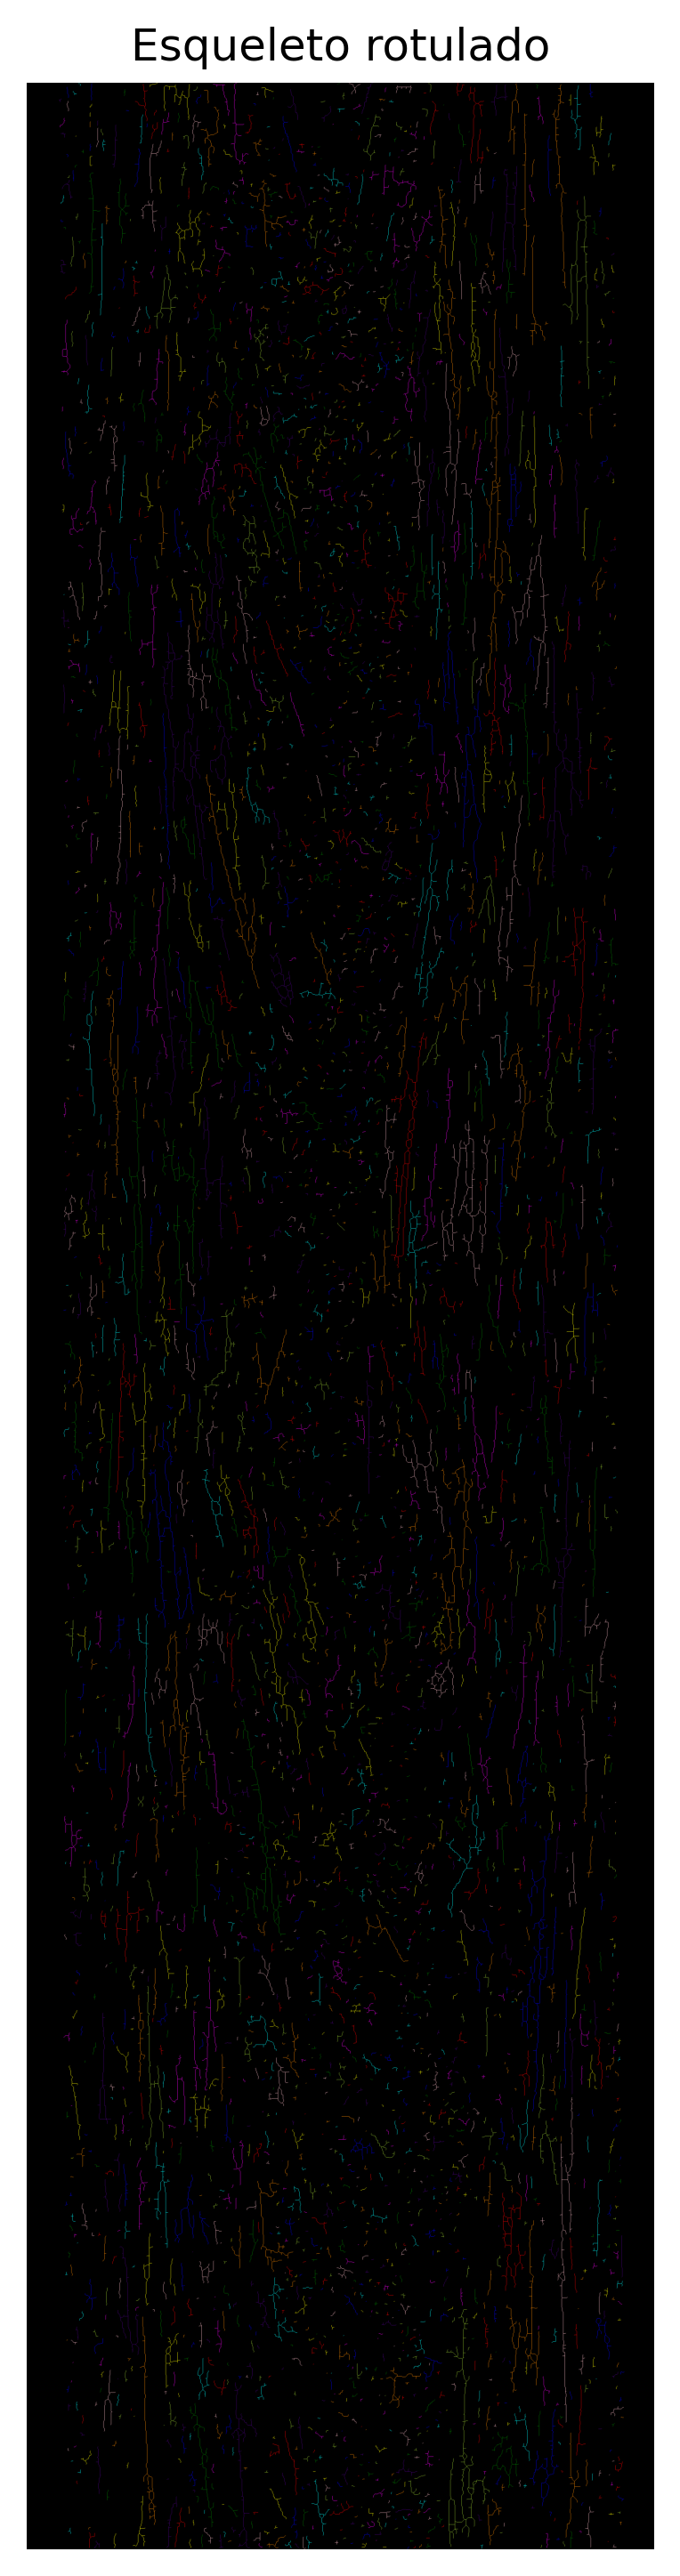

In [25]:
esqeueleto_rotulado = label(skeletonize(binaria_limpa), connectivity=2)

plt.figure(figsize=(10, 12), dpi=300)
plt.imshow(label2rgb(esqeueleto_rotulado, bg_label=0), cmap='gray')
plt.title("Esqueleto rotulado")
plt.axis('off')
plt.show()

In [69]:
skeleton_obj = Skeleton(esqueleto)
summary = summarize(skeleton_obj)

esqueleto_podado = np.copy(esqueleto)

# 2. Encontrar pontos de junção (NOVA LÓGICA)
# Concatena todas as IDs de nós (origem e destino) em uma única lista
todos_os_nos = pd.concat([summary['node-id-src'], summary['node-id-dst']], ignore_index=True)

# Conta a ocorrência de cada ID de nó
contagem_nos = todos_os_nos.value_counts()

# Junções são os nós que aparecem mais de 2 vezes
pontos_de_juncao = contagem_nos[contagem_nos > 2].index.tolist()

print(f"Encontrados {len(pontos_de_juncao)} pontos de junção para análise.")

Encontrados 5046 pontos de junção para análise.


/tmp/ipykernel_26886/3363998707.py:2: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  summary = summarize(skeleton_obj)


In [81]:
esqueleto_podado = podar_esqueleto_por_orientacao(esqueleto, angulo_limite_graus=90)

/tmp/ipykernel_26886/2068440519.py:189: VisibleDeprecationWarning: separator in column name will change to _ in version 0.13; to silence this warning, use `separator='-'` to maintain current behavior and use `separator='_'` to switch to the new default behavior.
  summary = summarize(skeleton_obj)


Encontrados 5046 pontos de junção para análise.
Podando ramo 1817.0 na junção 126448 (ângulo: 142.4°)
Podando ramo 1817.0 na junção 126448 (ângulo: 82.9°)
Podando ramo 1817.0 na junção 126448 (ângulo: 0.0°)
Podando ramo 1817.0 na junção 126448 (ângulo: -99.5°)
Podando ramo 1224.0 na junção 82819 (ângulo: 84.3°)
Podando ramo 1224.0 na junção 82819 (ângulo: 9.5°)
Podando ramo 1224.0 na junção 82819 (ângulo: 180.0°)
Podando ramo 1224.0 na junção 82819 (ângulo: -101.3°)
Podando ramo 100.0 na junção 6084 (ângulo: 76.0°)
Podando ramo 100.0 na junção 6084 (ângulo: 7.1°)
Podando ramo 100.0 na junção 6084 (ângulo: 180.0°)
Podando ramo 100.0 na junção 6084 (ângulo: -78.7°)
Podando ramo 2772.0 na junção 187839 (ângulo: 81.9°)
Podando ramo 2772.0 na junção 187839 (ângulo: -166.0°)
Podando ramo 2772.0 na junção 187839 (ângulo: 0.0°)
Podando ramo 2772.0 na junção 187839 (ângulo: -97.1°)
Podando ramo 3362.0 na junção 218501 (ângulo: 78.7°)
Podando ramo 3362.0 na junção 218501 (ângulo: 11.3°)
Podando 

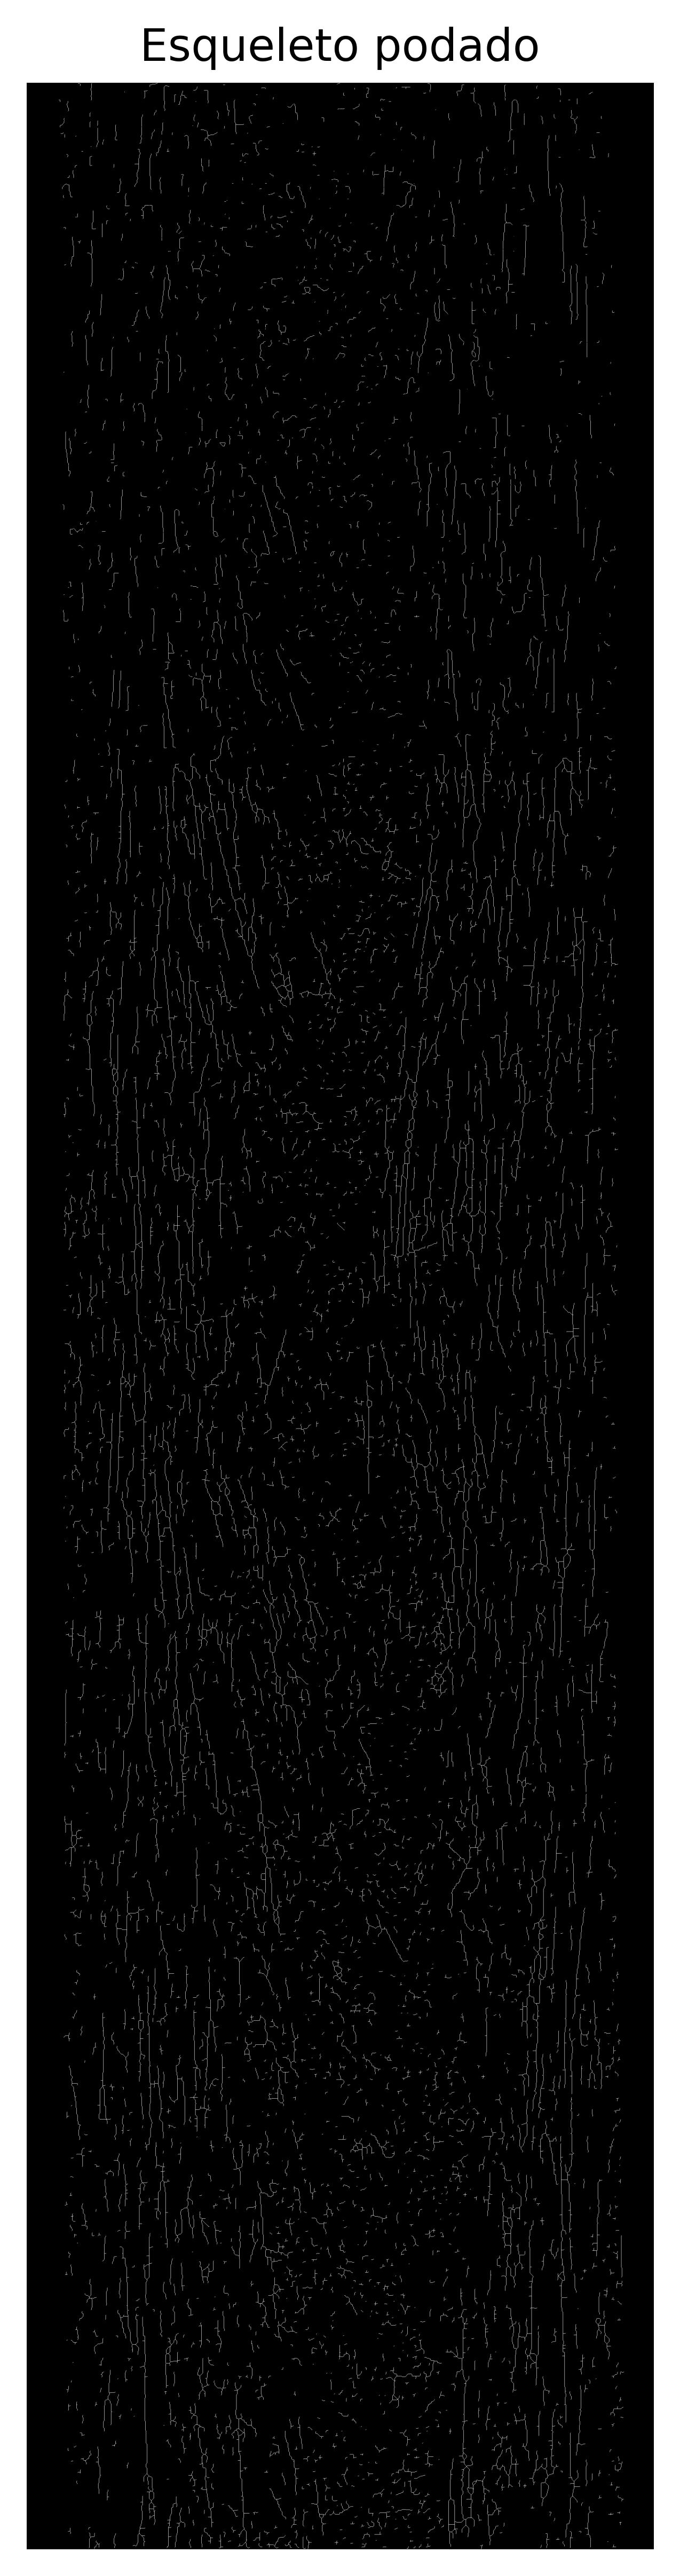

In [82]:
plt.figure(figsize=(10, 12), dpi=500)
plt.imshow((esqueleto_podado), cmap='gray')
plt.title("Esqueleto podado")
plt.axis('off')
plt.show()